In [1]:
#下載序列
!pip install biopython
from Bio import Entrez, SeqIO
Entrez.email = "a091062117502@gmail.com"

def get(acc):
    h = Entrez.efetch(db="nucleotide", id=acc, rettype="gb", retmode="text") #去抓資料，使用GenBank 格式
    return SeqIO.read(h, "genbank")

human = get("NM_000207")   # 人類 INS
mouse = get("NM_008387")   # 小鼠 Ins2
print(human.description)
print(mouse.description)



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 37.0 MB/s  0:00:00
Homo sapiens insulin (INS), transcript variant 1, mRNA
Mus musculus insulin II (Ins2), transcript variant 2, mRNA


In [2]:
#計算GC含量
from Bio.SeqUtils import gc_fraction
for name, r in [("Human", human), ("Mouse", mouse)]:
    print(name, len(r.seq), round(gc_fraction(r.seq)*100, 1), "%")


Human 465 63.9 %
Mouse 485 56.5 %


In [3]:
#定義一個功能從mRNA中找出CDS，再轉譯成蛋白質
def protein(rec):
    for f in rec.features:
        if f.type == "CDS":
            return f.extract(rec.seq).translate(to_stop=True)

p_h, p_m = protein(human), protein(mouse)
print(p_h); print(p_m)


MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN
MALWMRFLPLLALLFLWESHPTQAFVKQHLCGSHLVEALYLVCGERGFFYTPMSRREVEDPQVAQLELGGGPGAGDLQTLALEVAQQKRGIVDQCCTSICSLYQLENYCN


In [4]:
#兩筆資料進行比對
from Bio import Align
from Bio.Align import substitution_matrices
al = Align.PairwiseAligner()
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score = -10
al.extend_gap_score = -0.5
aln = al.align(p_h, p_m)[0]
a, b = aln[0], aln[1]
same = sum(1 for x, y in zip(a, b) if x == y and x != "-")
print("比對分數:", aln.score)
print("相同比例:", round(same/len(a)*100, 1), "%")
print(aln)


比對分數: 478.0
相同比例: 81.8 %
target            0 MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAED
                  0 ||||||.|||||||.||...|..|||.|||||||||||||||||||||||||..|||.||
query             0 MALWMRFLPLLALLFLWESHPTQAFVKQHLCGSHLVEALYLVCGERGFFYTPMSRREVED

target           60 LQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN 110
                 60 .||.|.|||||||||.||.||||...||||||.||||||||||||||||| 110
query            60 PQVAQLELGGGPGAGDLQTLALEVAQQKRGIVDQCCTSICSLYQLENYCN 110



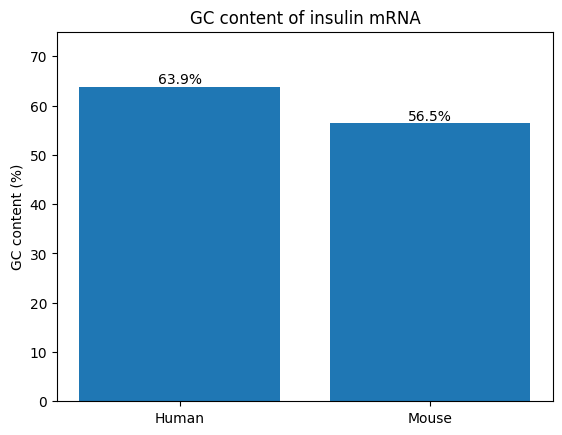

In [5]:
#畫出圖表
import matplotlib.pyplot as plt
vals = [gc_fraction(human.seq)*100, gc_fraction(mouse.seq)*100]
bars = plt.bar(["Human", "Mouse"], vals)
plt.bar_label(bars, fmt='%.1f%%')
plt.ylabel("GC content (%)")
plt.title("GC content of insulin mRNA")
plt.ylim(0, 75)

plt.show()